# Türkçe Tweetlerde Siber Zorbalık Tespiti

**Veri:** 5.000 Türkçe tweet (2.500 zorbalık, 2.500 zorbalık değil). Metnin yanında 25 sayısal özellik var: retweet/beğeni sayısı, gönderenin takipçi sayısı, hesap yaşı, argo kelime sayısı vb.

In [6]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.metrics import classification_report, confusion_matrix, f1_score

In [7]:
# Grafik ayarları: tüm grafikler aynı görünsün diye
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6e6e3",
    "axes.axisbelow": True,
    "figure.dpi": 110,
})
MAVI, TURUNCU = "#2a78d6", "#eb6834"

## 1. Veriyi Okuma ve Temizleme

In [8]:
VERI_DOSYASI = next(Path("veriler").rglob("comp*cyberbullying*.csv"))
print("Okunan dosya:", VERI_DOSYASI)

turkce = pd.read_csv(VERI_DOSYASI, encoding="utf-8")

print("Satır, sütun:", turkce.shape)
print("\nSınıf dağılımı:")
print(turkce["IsCyberbullying"].value_counts())

Okunan dosya: veriler\Data for Cyberbullying Detection Utilizing Social Media Features\compherensive_cyberbullying_dataset_including_social_media_attributes.csv
Satır, sütun: (5000, 27)

Sınıf dağılımı:
IsCyberbullying
False    2500
True     2500
Name: count, dtype: int64


In [9]:
print(turkce[["Text", "IsCyberbullying"]].head(6).to_string()) # ilk 6 veri

                                                                                                                                       Text  IsCyberbullying
0                    galatasaray spor kulübü hakkındaki son gelişme ve haberleri bulabileceğiniz twitter sayfasi gün itibari ile açılmıştır            False
1                                 kevin durant umraniye de kaybolmus allah rizasi icin goren yolu tarif etsin meydan da nike magazasindayiz            False
2                            avrupa şampiyonası heyecanı devam ediyor çek cumhuriyeti iskoçya 1 1 65 x 3 20 2 3 60 hemen iddaa oynamak için            False
3  zorunlu açiklama alex de souza ile herhangi bir temasımız olmamış gündemimizde de bu oyuncu ile ilgili bir düşüncemiz de bulunmamaktadır            False
4                                                       anayasanın 66 maddesi türk devletine vatandaşlık bağı ile bağlı olan herkes türktür            False
5                                                         

In [10]:
print("Başlangıç:", len(turkce))

# Aynı metin farklı etiketle geçiyorsa (çelişkili) at
etiket_sayisi = turkce.groupby("Text")["IsCyberbullying"].transform("nunique")
print("Çelişkili etiketli satır:", (etiket_sayisi > 1).sum())
turkce = turkce[etiket_sayisi == 1]

# Tekrar eden metinleri at
print("Tekrar eden metin       :", turkce["Text"].duplicated().sum())
turkce = turkce.drop_duplicates(subset="Text")

# Mantıksız değer
hatali_yas = turkce["SenderAccountYears"] > 20
print("Hatalı hesap yaşı       :", hatali_yas.sum())
turkce = turkce[~hatali_yas]

turkce["Zorbalik"] = turkce["IsCyberbullying"].astype(int)    # True/False
print("\nTemizlik sonrası:", len(turkce))

Başlangıç: 5000
Çelişkili etiketli satır: 4
Tekrar eden metin       : 36
Hatalı hesap yaşı       : 4

Temizlik sonrası: 4956


## 2. İki Sınıf Hangi Özelliklerde Farklı?

In [11]:
ozellikler = ["Favorites#", "Retweets#", "SenderFollowers#", "SenderAccountYears",
              "SlangWords#", "Mentions#", "Words#"]

medyanlar = turkce.groupby("Zorbalik")[ozellikler].median().T
medyanlar.columns = ["Zorbalık değil", "Zorbalık"]
print(medyanlar)

                    Zorbalık değil  Zorbalık
Favorites#                    27.0       0.0
Retweets#                      5.0       0.0
SenderFollowers#            2584.0     231.0
SenderAccountYears             3.0       2.0
SlangWords#                    0.0       1.0
Mentions#                      0.0       1.0
Words#                        11.0      10.0


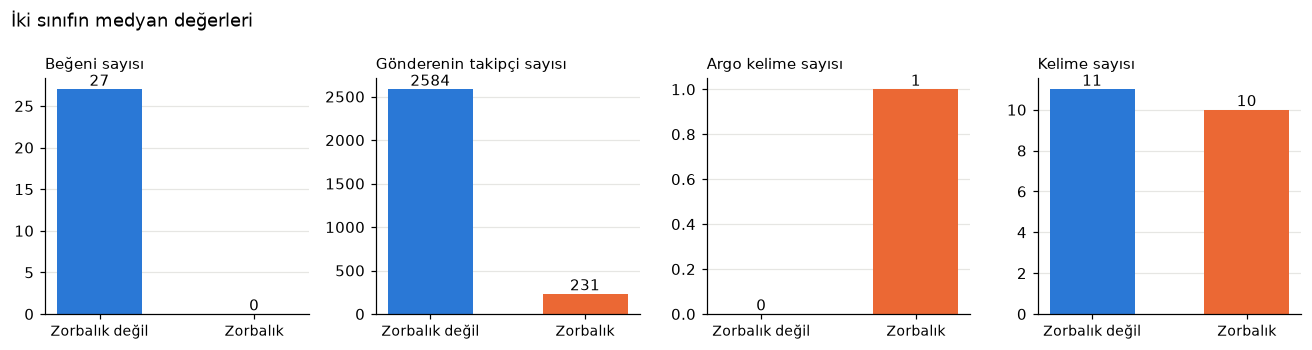

In [13]:
# Grafik: Dört özellikte iki sınıfın medyanı (her özellik kendi ölçeğinde)
secilen = {
    "Favorites#":       "Beğeni sayısı",
    "SenderFollowers#": "Gönderenin takipçi sayısı",
    "SlangWords#":      "Argo kelime sayısı",
    "Words#":           "Kelime sayısı",
}

fig, eksenler = plt.subplots(1, 4, figsize=(12, 3.2))
for ax, (sutun, etiket) in zip(eksenler, secilen.items()):
    medyan = turkce.groupby("Zorbalik")[sutun].median()
    ax.bar(["Zorbalık değil", "Zorbalık"], medyan.values, color=[MAVI, TURUNCU], width=0.55)
    for x, deger in enumerate(medyan.values):
        ax.text(x, deger, f"{deger:.0f}", ha="center", va="bottom")
    ax.set_title(etiket, loc="left", fontsize=10)
    ax.grid(axis="x", visible=False)
    ax.tick_params(axis="x", labelsize=9)

fig.suptitle("İki sınıfın medyan değerleri", x=0.01, ha="left")
plt.tight_layout()
plt.show()

## 3. Metin Modeli

In [14]:
egitim_x, test_x, egitim_y, test_y = train_test_split(
    turkce["Text"], turkce["Zorbalik"],
    test_size=0.2, stratify=turkce["Zorbalik"], random_state=42,
)

metin_modeli = make_pipeline(
    TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True),
    LogisticRegression(max_iter=2000),
)
metin_modeli.fit(egitim_x, egitim_y)
tahmin = metin_modeli.predict(test_x)

print(classification_report(test_y, tahmin, target_names=["Zorbalık değil", "Zorbalık"], digits=3))
f1_metin = f1_score(test_y, tahmin)

                precision    recall  f1-score   support

Zorbalık değil      0.871     0.867     0.869       497
      Zorbalık      0.867     0.871     0.869       495

      accuracy                          0.869       992
     macro avg      0.869     0.869     0.869       992
  weighted avg      0.869     0.869     0.869       992



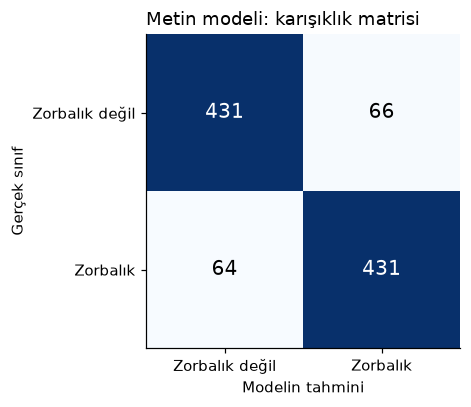

In [16]:
# Grafik: Karışıklık matrisi
matris = confusion_matrix(test_y, tahmin)
siniflar = ["Zorbalık değil", "Zorbalık"]

fig, ax = plt.subplots(figsize=(4.5, 3.8))
ax.imshow(matris, cmap="Blues")
for i in range(2):
    for j in range(2):
        renk = "white" if matris[i, j] > matris.max() / 2 else "black"
        ax.text(j, i, matris[i, j], ha="center", va="center", color=renk, fontsize=13)
ax.set_xticks([0, 1], siniflar)
ax.set_yticks([0, 1], siniflar)
ax.set_xlabel("Modelin tahmini")
ax.set_ylabel("Gerçek sınıf")
ax.set_title("Metin modeli: karışıklık matrisi", loc="left")
ax.grid(False)
plt.tight_layout()
plt.show()

## 4. Deney: Sadece Beğeni + Retweet ile Ne Kadar Skor Alıyoruz?

In [17]:
X_populerlik = np.log1p(turkce[["Favorites#", "Retweets#"]])

egitim_x, test_x, egitim_y, test_y = train_test_split(
    X_populerlik, turkce["Zorbalik"],
    test_size=0.2, stratify=turkce["Zorbalik"], random_state=42,
)

populerlik_modeli = LogisticRegression()
populerlik_modeli.fit(egitim_x, egitim_y)
f1_populerlik = f1_score(test_y, populerlik_modeli.predict(test_x))

print(f"Sadece metin            → F1 = {f1_metin:.3f}")
print(f"Sadece beğeni + retweet → F1 = {f1_populerlik:.3f}")

Sadece metin            → F1 = 0.869
Sadece beğeni + retweet → F1 = 0.813


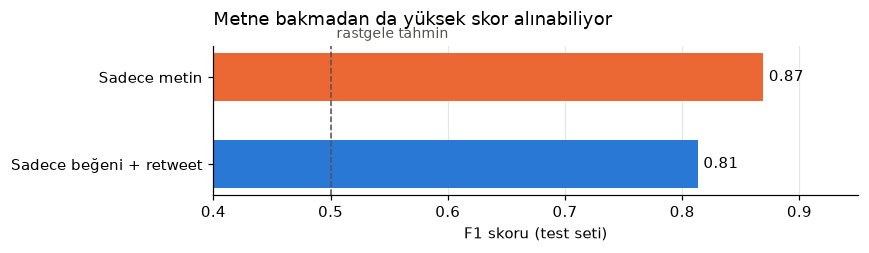

In [19]:
# Grafik: Metin modeli ile popülerlik modelinin karşılaştırılması
skorlar = pd.Series({"Sadece beğeni + retweet": f1_populerlik, "Sadece metin": f1_metin})

fig, ax = plt.subplots(figsize=(8, 2.4))
ax.barh(skorlar.index, skorlar.values, color=[MAVI, TURUNCU], height=0.55)
ax.axvline(0.5, color="#52514e", linestyle="--", linewidth=1)
ax.text(0.505, 1.45, "rastgele tahmin", fontsize=9, color="#52514e")
for i, deger in enumerate(skorlar.values):
    ax.text(deger + 0.005, i, f"{deger:.2f}", va="center")
ax.set_xlim(0.4, 0.95)
ax.set_xlabel("F1 skoru (test seti)")
ax.set_title("Metne bakmadan da yüksek skor alınabiliyor", loc="left", pad=14)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

## 5.Sonuç

Zorbalık olmayan örneklerin ilk altısı kulüp haberi, bahis reklamı ve anayasa alıntısı gibi kurumsal içerikler bunlar zaten çok takipçili ve çok etkileşim alan hesaplardan gelir. Model bu durumda zorbalığı değil, “bireysel ve düşük etkileşimli tweet” ile “kurumsal ve popüler tweet” ayrımını öğrenmiş olabilir. Bu yüzden 0,869'luk skor, gerçek hayatta zorbalık tespit edebileceği anlamına gelmez.